# GNN ENCODER

In [1]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

## Datasets

### RavenDataset

In [9]:
import random

import torch
from torch.utils.data import DataLoader

from hri_gnn.datasets import RavenDataset, raven_flat_collate
from hri_gnn.config.const import Configuration

torch.manual_seed(92)
random.seed(92)

DATASET_NAME = 'raven-100'
PERCENTAGE_LIMIT = 0.1
BATCH_SIZE = 10
SPLIT = 'test'
active_configs = [Configuration.IN_DISTRIBUTE_FOUR_OUT_CENTER_SINGLE.value]

test_dataset_raven_100 = RavenDataset(dataset= DATASET_NAME, 
                                       split='test', 
                                       percentage_limit=PERCENTAGE_LIMIT, 
                                       configs=active_configs)

test_dataloader = DataLoader(dataset=test_dataset_raven_100, 
                              batch_size=BATCH_SIZE, 
                              shuffle= (SPLIT == 'train'), 
                              collate_fn=raven_flat_collate)

### PreComputedRavenDataset

In [3]:
import random

import torch
from torch.utils.data import DataLoader

from hri_gnn.datasets.precomputed import PrecomputedRavenDataset, precomputed_collate
from hri_gnn.config.const import Configuration

torch.manual_seed(92)
random.seed(92)

DATASET_NAME = 'raven-100'
PERCENTAGE_LIMIT = 0.1
BATCH_SIZE = 10
SPLIT = 'test'
active_configs = [Configuration.IN_DISTRIBUTE_FOUR_OUT_CENTER_SINGLE.value]

test_precomputed_dataset = PrecomputedRavenDataset(dataset=DATASET_NAME,
                                                   split=SPLIT,
                                                   percentage_limit=PERCENTAGE_LIMIT,
                                                   configs=active_configs)

test_precomputed_dataloader = DataLoader(dataset=test_precomputed_dataset,
                                         batch_size=BATCH_SIZE,
                                         shuffle= SPLIT == 'train',
                                         collate_fn=precomputed_collate,
                                         num_workers=4,
                                         persistent_workers=True,
                                         pin_memory=True)

#### RavenCnnEncoder

needed in the `GraphBuilder` to build graphs on the fly during the training session

In [4]:
from hri_gnn.models import RavenCnnEncoder
from hri_gnn.utils import paths
# load the saved model 
output_path = paths.get_output_path()
raven_encoder = RavenCnnEncoder()
raven_encoder.load_state_dict(torch.load(f=output_path/'models'/'raven_cnn_encoder_final.pth'))

<All keys matched successfully>

#### Original Raw `BATCH`

In [29]:
from itertools import islice
batch = list(islice(test_dataloader,1))[0]
conf_prblm_batch = torch.stack([batch[5],batch[6], batch[8]]).unique(dim=-1)
numb_prblm= conf_prblm_batch.shape[1]
zipped = zip(conf_prblm_batch[0].tolist(), conf_prblm_batch[1].tolist(), conf_prblm_batch[2].tolist())
problem_ids = [(i,j,k) for i,j,k in zipped] 
print(f"batch problems count: {numb_prblm}, (cnfg_id, prblm_id, btc_id): {problem_ids}")

print(f"dataset length: {len(test_dataset_raven_100)}")

batch problems count: 2, (cnfg_id, prblm_id, btc_id): [(4, 8, 1), (4, 79, 0)]
dataset length: 2


#### Precomputed `BATCH`

In [31]:
from hri_gnn.models.gnn_encoder import group_layouts_by_panel
from collections import defaultdict
precomputed_count = 0
problems_graphs = defaultdict(list)
precomputed_batch = list(islice(test_precomputed_dataloader,1))[0]

pyg_batch, all_layout_keys, all_config_ids, all_problem_ids = precomputed_batch
problems = {(all_config_ids[i], all_problem_ids[i]) for i in range(len(all_problem_ids))}

n_problems = pyg_batch.num_graphs // len(range(8, 16))
print(f"Number of problems in the batch: {n_problems}")
print(f"Number of Graphs in the batch : {pyg_batch.num_graphs}, each problem have 8 candidate graphs")
for problem in problems :
    print(f" * problem: {problem}")
    graphs = [str(problem)+f'_C{i}' for i in range(8,16) ]
    print(f" * Graphs:\n - {graphs}")

print(f"dataset length: {len(test_precomputed_dataset)}")

Number of problems in the batch: 2
Number of Graphs in the batch : 16, each problem have 8 candidate graphs
 * problem: (4, 79)
 * Graphs:
 - ['(4, 79)_C8', '(4, 79)_C9', '(4, 79)_C10', '(4, 79)_C11', '(4, 79)_C12', '(4, 79)_C13', '(4, 79)_C14', '(4, 79)_C15']
 * problem: (4, 8)
 * Graphs:
 - ['(4, 8)_C8', '(4, 8)_C9', '(4, 8)_C10', '(4, 8)_C11', '(4, 8)_C12', '(4, 8)_C13', '(4, 8)_C14', '(4, 8)_C15']
dataset length: 2


#### RavenGnnEncoder

In [33]:
from itertools import islice
from hri_gnn.models import RavenGnnEncoder
from hri_gnn.config.const import GRAPH_EDGE_TYPES, GRAPH_NODE_TYPES
from hri_gnn.models.gnn_encoder import CandidateScorer, score_and_loss_for_batch

active_edge_types = None
hidden_dim = 64 
num_layers = 3
dropout = 0.1

gnn_encoder = RavenGnnEncoder(GRAPH_NODE_TYPES, hidden_dim, num_layers, active_edge_types, dropout)

x_dict = {'entity': pyg_batch['entity'].x, 'layout': pyg_batch['layout'].x}
edge_index_dict = {edge_type: pyg_batch[edge_type].edge_index for edge_type in GRAPH_EDGE_TYPES.keys()}
edge_attr_dict = {edge_type: pyg_batch[edge_type].edge_attr for edge_type in GRAPH_EDGE_TYPES.keys()}

problems = {(all_config_ids[i], all_problem_ids[i]) for i in range(len(all_problem_ids))}
graphs = [str(problem)+f'_C{i}' for problem in problems for i in range(8,16) ]

h_dict = gnn_encoder(x_dict, edge_index_dict, edge_attr_dict)
print(f"The Origninal layout representation is: \n{x_dict["layout"]} \n shape {x_dict["layout"].shape}")
print(f"The new layout node representation afeter {num_layers} is :\n{h_dict["layout"]} \n shape {h_dict["layout"].shape}")


print(f"- targets for every graph in the batch:\n{pyg_batch.y}")

The Origninal layout representation is: 
tensor([[  7.7260,  91.6392,   0.0000,  ...,   0.0000,   1.0000,   0.0000],
        [ 20.2757, 112.2267,   0.0000,  ...,   0.0000,   3.0000,   1.0000],
        [  6.1260,  87.3386,   0.0000,  ...,   0.0000,   1.0000,   0.0000],
        ...,
        [ 27.9962,  46.3914,   0.0000,  ...,   0.0000,   2.0000,   1.0000],
        [  6.3909,  89.3685,   0.0000,  ...,   0.0000,   1.0000,   0.0000],
        [ 35.3351,  38.9360,   0.0000,  ...,   0.0000,   4.0000,   1.0000]]) 
 shape torch.Size([288, 97])
The new layout node representation afeter 3 is :
tensor([[ 1.6296,  0.4347,  0.3699,  ..., -0.2658, -0.1945,  0.9384],
        [ 0.7881, -1.0066,  0.4068,  ..., -0.7160, -0.0671,  0.5610],
        [ 0.0811, -0.2826,  0.3811,  ...,  0.0391, -0.3413,  0.9734],
        ...,
        [ 1.6778,  0.7591,  0.1628,  ..., -0.9116, -0.4268, -0.3684],
        [ 1.2182, -0.2895,  0.7094,  ..., -0.6107,  0.2546,  0.2870],
        [ 0.4483,  0.0265, -1.0998,  ..., -0.38

In [8]:
scorer  = CandidateScorer(hidden_dim)

scores = score_and_loss_for_batch(h_dict['layout'], pyg_batch['layout'].batch, all_layout_keys,
                                            pyg_batch.y, scorer, range(8, 16) , n_problems)
print(f"- Scores per problem: \n{scores[0]}")
print(f"- Losses per problem: \n{scores[1]}")
print(f"- Mean loss: \n{scores[2]}")


- Scores per problem: 
[tensor([-0.0355,  0.1368, -0.0888, -0.0477,  0.1284, -0.0362, -0.0871, -0.1138],
       grad_fn=<SelectBackward0>), tensor([ 0.0139, -0.0612, -0.1373, -0.1244, -0.0384, -0.1356, -0.1465, -0.0799],
       grad_fn=<SelectBackward0>)]
- Losses per problem: 
[tensor(2.1012, grad_fn=<NllLossBackward0>), tensor(2.1279, grad_fn=<NllLossBackward0>)]
- Mean loss: 
2.1145143508911133


In [20]:
flat_crops                = batch[0] # crops               ,shape: [xxx, 1, 80, 80]
flat_attributes           = batch[1] # attributes          ,shape: [xxx, 4]
flat_bboxes               = batch[2] # bbox                ,shape: [xxx, 4] 
flat_panel_indices        = batch[3] # panel indices       ,shape: [xxx]
flat_component_indices    = batch[4] # component indices   ,shape: [xxx]
flat_config_indices       = batch[5] # config indices      ,shape: [xxx]
flat_problem_indices      = batch[6] # problems indices    ,shape: [xxx]
flat_problem_targets      = batch[7] # problems targets    ,shape: [xxx]
flat_batch_indices        = batch[8] # batch indices       ,shape: [xxx]

In [21]:
from hri_gnn.models import build_hetero_data_batch, build_pyg_batch

hetero_data_dict, meta_dict = build_hetero_data_batch(batch, raven_encoder, include_columns= True, candidate_ids=range(8,16), device= None)
pyg_batch, batched_layout_keys, keys_order = build_pyg_batch(hetero_data_dict, meta_dict)

In [22]:
print(f"number of graphs in the batch: {len(hetero_data_dict)}\n")
print(f"graph names: {hetero_data_dict.keys()}\n")
problem = '(4, 8, 1)'
candidate = 'c10'
graph = '(4, 8, 1)'+'_'+ 'c10'
hetero_data = hetero_data_dict[graph]

print(f"hetero_data entity x shape:\n{hetero_data['entity'].x.shape}\n")
print(f"hetero_data layout x shape:\n{hetero_data['layout'].x.shape}\n")

print(f"pyg_batch layout x shape:\n{pyg_batch['layout'].x.shape}\n")

layout_contains_entity = hetero_data[('layout', 'contains', 'entity')]
entity_entity_intra_panel = hetero_data[('entity', 'intra_panel', 'entity')]
entity_entity_inter_panel = hetero_data[('entity', 'inter_panel_entity', 'entity')]
layout_layout_inter_panel = hetero_data[('layout', 'inter_panel_layout', 'layout')]
entity_belongs_to_layout = hetero_data[('entity', 'belongs_to', 'layout')]
print(f"hetero_data edges:\n")
print(f" - ('layout', 'contains', 'entity'): \n\t edge index shape:{layout_contains_entity.edge_index.shape}\n\t edge attr shape: {layout_contains_entity.edge_attr.shape}")
print(f" - ('entity', 'intra_panel', 'entity'): \n\t edge index: {entity_entity_intra_panel.edge_index.shape}\n\t edge attr shape: {entity_entity_intra_panel.edge_attr.shape}")
print(f" - ('entity', 'inter_panel_entity', 'entity'): \n\t edge index: {entity_entity_inter_panel.edge_index.shape}\n\t edge attr shape: {entity_entity_inter_panel.edge_attr.shape}")
print(f" - ('layout', 'inter_panel_layout', 'layout'): \n\t edge index: {layout_layout_inter_panel.edge_index.shape}\n\t edge attr shape: {layout_layout_inter_panel.edge_attr.shape}")
print(f" - ('entity', 'belongs_to', 'layout'): \n\t edge index :{entity_belongs_to_layout.edge_index.shape}\n\t edge attr shape: {entity_belongs_to_layout.edge_attr.shape}")

number of graphs in the batch: 16

graph names: dict_keys(['(4, 79, 0)_c8', '(4, 79, 0)_c9', '(4, 79, 0)_c10', '(4, 79, 0)_c11', '(4, 79, 0)_c12', '(4, 79, 0)_c13', '(4, 79, 0)_c14', '(4, 79, 0)_c15', '(4, 8, 1)_c8', '(4, 8, 1)_c9', '(4, 8, 1)_c10', '(4, 8, 1)_c11', '(4, 8, 1)_c12', '(4, 8, 1)_c13', '(4, 8, 1)_c14', '(4, 8, 1)_c15'])

hetero_data entity x shape:
torch.Size([27, 86])

hetero_data layout x shape:
torch.Size([18, 97])

pyg_batch layout x shape:
torch.Size([288, 97])

hetero_data edges:

 - ('layout', 'contains', 'entity'): 
	 edge index shape:torch.Size([2, 27])
	 edge attr shape: torch.Size([27, 1])
 - ('entity', 'intra_panel', 'entity'): 
	 edge index: torch.Size([2, 26])
	 edge attr shape: torch.Size([26, 2])
 - ('entity', 'inter_panel_entity', 'entity'): 
	 edge index: torch.Size([2, 80])
	 edge attr shape: torch.Size([80, 23])
 - ('layout', 'inter_panel_layout', 'layout'): 
	 edge index: torch.Size([2, 72])
	 edge attr shape: torch.Size([72, 97])
 - ('entity', 'belon

***RavenGnnModel***

In [99]:
from hri_gnn.metrics import gnn_predictions
from hri_gnn.models import RavenGnnModel
from hri_gnn.metrics import gnn_predictions
from hri_gnn.config.const import GRAPH_NODE_TYPES

active_edge_types = None
hidden_dim = 64 
num_layers = 3
dropout = 0.1

raven_gnn_model = RavenGnnModel(in_dims=GRAPH_NODE_TYPES, 
                                hidden_dim=hidden_dim, 
                                num_layers=num_layers, 
                                active_edge_types=active_edge_types, 
                                candidate_ids=range(8,16), 
                                dropout=dropout)

scores_per_problem, losses_per_problem, mean_loss = raven_gnn_model(pyg_batch, batched_layout_keys, n_problems)

print(scores_per_problem, losses_per_problem, mean_loss)

print(gnn_predictions(scores_per_problem, pyg_batch.y ,range(8,16)))


[tensor([-0.2284, -0.3297, -0.3663, -0.3869, -0.3372, -0.4668, -0.4230, -0.4536],
       grad_fn=<SelectBackward0>), tensor([-0.4068, -0.5169, -0.3601, -0.4557, -0.4363, -0.3102, -0.4111, -0.3745],
       grad_fn=<SelectBackward0>)] [tensor(1.9365, grad_fn=<NllLossBackward0>), tensor(1.9824, grad_fn=<NllLossBackward0>)] tensor(1.9595, grad_fn=<MeanBackward0>)
(tensor([0, 5]), tensor([0, 5]))


In [23]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [100]:
# Python imports 
import random 
from collections import defaultdict
from itertools import islice
from pprint import pp
import json

# PyTorch imports 
import torch
import torch.nn as nn 
from torch.utils.data import DataLoader

# matplotlib imports
import matplotlib.pyplot as plt 

# HRI_GNN imports
from hri_gnn.config.const import Configuration, SLOT_TABLE, MAX_SLOTS, GRAPH_NODE_TYPES, GRAPH_EDGE_TYPES
from hri_gnn.utils import paths
from hri_gnn.datasets import raven_flat_collate
from hri_gnn.datasets import RavenDataset
from hri_gnn.models.cnn_encoder import RavenCnnEncoder
from hri_gnn.models.gnn_encoder import RavenGnnModel  #,RavenGnnEncoder , CandidateScorer , score_and_loss_for_batch
#from hri_gnn.models import graph_builder as gb
#from hri_gnn.losses import compute_candidate_loss
from hri_gnn.trainers import GnnTrainer

In [101]:
# load the saved model 

output_path = paths.get_output_path()

raven_encoder = RavenCnnEncoder()

raven_encoder.load_state_dict(torch.load(f=output_path/'models'/'raven_cnn_encoder_final.pth'))

<All keys matched successfully>

In [102]:
from hri_gnn.config.const import SPLITS
torch.manual_seed(92)
random.seed(92)

DATASET = 'raven-100'
PERCENTAGE_LIMIT = 0.1
BATCH_SIZE = 10

active_configs = [Configuration.CENTER_SINGLE.value]

datatsets_dict = {}
dataloaders_dict = {}

for config in Configuration.all()[:1]:
    for split in SPLITS:
        datatsets_dict[f"{config}_{split}"] = RavenDataset(dataset=DATASET,
                                              split=split,
                                              percentage_limit=PERCENTAGE_LIMIT,
                                              configs=[config])
        dataloaders_dict[f"{config}_{split}"] = DataLoader(
                                                dataset=datatsets_dict[f"{config}_{split}"],
                                                batch_size=BATCH_SIZE,
                                                shuffle= split == 'train',
                                                collate_fn=raven_flat_collate)

In [103]:
for config in Configuration.all()[:1]:
    print("="*60)
    for split in SPLITS:
        print(f"{config}_{split}: \t\t {len(datatsets_dict[f"{config}_{split}"])}")

center_single_train: 		 6
center_single_test: 		 2
center_single_val: 		 2


***GnnTrainer***

In [24]:
output_path = paths.get_output_path()
paths.output_paths(output_path)

gnn_model = RavenGnnModel(GRAPH_NODE_TYPES, hidden_dim=32, num_layers=3).to("cuda")
optimizer = torch.optim.Adam(gnn_model.parameters(), lr=1e-3)

# homogeniuos edges
option_A = [ ('entity', 'intra_panel', 'entity'),('entity', 'inter_panel_entity', 'entity'),('layout', 'inter_panel_layout', 'layout')]
# layout edges only
option_B = [ ('layout', 'inter_panel_layout', 'layout')]
# inter panels only 
option_C = [ ('entity', 'inter_panel_entity', 'entity'), ('layout', 'inter_panel_layout', 'layout')]
# entity edges only
option_D = [ ('entity', 'intra_panel', 'entity'),('entity', 'inter_panel_entity', 'entity')]

train_only = False
active_edge_types = None # all edges are activated
include_columns = True 
epochs = 10

history_dict = {}
for config in Configuration.all()[:1]:
    print(f"Training {config}....")

    # 1. Instantiate the GNN model (fresh instace for each config)
    gnn_trainer = GnnTrainer(gnn_model, raven_encoder, optimizer, metrics=None, node_types= None, 
                             active_edge_types= active_edge_types, 
                             include_columns=include_columns, device="cuda", output_path= None)
    # 2. Train the GNN model
    history_dict[config] = gnn_trainer.fit(dataloaders_dict[f"{config}_train"] , 
                                           dataloaders_dict[f"{config}_test"], 
                                           epochs=epochs, 
                                           max_grad_norm=None, 
                                           checkpoint_name_prefix = config,
                                           check_frequency=0,
                                           save_final_version= False,
                                           verbose=True, 
                                           train_only= train_only)
    # 3. Saving the training history
    # history_path = output_path/"history"/"gnn"/f"training_history_{config}.json"
    # with open(history_path, 'w') as f:
    #     json.dump(history_dict[config], f, indent=2)
    # print(f"\n[OK] Training history {config} saved : {history_path}")

    print("="*80)

Training center_single....


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/10 - Train Loss: 2.0477 | Train Acc: 0.1045 | Test Loss: 2.0159 | Test Acc: 0.1266
Epoch 2/10 - Train Loss: 1.9983 | Train Acc: 0.1300 | Test Loss: 1.9746 | Test Acc: 0.1533
Epoch 3/10 - Train Loss: 1.9657 | Train Acc: 0.1555 | Test Loss: 1.9557 | Test Acc: 0.1628
Epoch 4/10 - Train Loss: 1.9351 | Train Acc: 0.1714 | Test Loss: 1.9548 | Test Acc: 0.1845
Epoch 5/10 - Train Loss: 1.9255 | Train Acc: 0.1767 | Test Loss: 1.9345 | Test Acc: 0.1724
Epoch 6/10 - Train Loss: 1.9023 | Train Acc: 0.1893 | Test Loss: 1.9152 | Test Acc: 0.1927
Epoch 7/10 - Train Loss: 1.8785 | Train Acc: 0.2009 | Test Loss: 1.9244 | Test Acc: 0.1826
Epoch 8/10 - Train Loss: 1.8674 | Train Acc: 0.2037 | Test Loss: 1.8867 | Test Acc: 0.2074
Epoch 9/10 - Train Loss: 1.8460 | Train Acc: 0.2211 | Test Loss: 1.8804 | Test Acc: 0.2061
Epoch 10/10 - Train Loss: 1.8139 | Train Acc: 0.2326 | Test Loss: 1.8452 | Test Acc: 0.2277

Training finished!....
- Train (Test) number of problems: [4708] ([1572])
- Train (Test)

In [ ]:
history_dict


In [ ]:
# read json history_dict 
#output_path = paths.get_output_path()
train_only=False
for config in Configuration.all()[:1]:
    # history_dict_path = output_path /"history"/"gnn"/f"training_history_{config}.json"
    # with open(history_dict_path, 'r') as json_file:
    #     history_dict = json.load(json_file)
        # print(history_dict)
    cfg_history_dict = history_dict[config]
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,10))
    subtitle = f"{config} Loss and Accuracy \n"
    subtitle +=f"NB problems Train (Test): {cfg_history_dict["train_number_of_problems"]} ({cfg_history_dict["test_number_of_problems"]})\n"
    subtitle +=f"NB Entity Train (Test): {cfg_history_dict["train_entity"]} ({cfg_history_dict["test_entity"]})\n" 
    subtitle +=f"NB Layout Train (Test): {cfg_history_dict["train_layout"]} ({cfg_history_dict["test_layout"]})" 

    fig.suptitle(subtitle, fontsize=11)
    axes[0].plot(range(epochs), cfg_history_dict['train_loss'] , color='blue', linewidth=2, label='train loss')
    if not train_only:
        axes[0].plot(range(epochs), cfg_history_dict['test_loss'] , color='red', linewidth=2, label='test loss')
    axes[0].set_title(f'Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.2, color='#555')
    axes[1].plot(range(epochs), cfg_history_dict['train_accuracy'],color="black",linewidth=2, label=f'train accuracy')
    if not train_only:
        axes[1].plot(range(epochs), cfg_history_dict['test_accuracy'],color="green",linewidth=2, label=f'test accuracy')
    axes[1].set_title(f'accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.2, color='#555')

    # gnn_curves_path = output_path/"metric_curves"/"gnn"/f"{config}_loss_accuracy.png"
    # plt.savefig(gnn_curves_path)
    # print(f"\n[OK] {config} curves saved to {gnn_curves_path}")



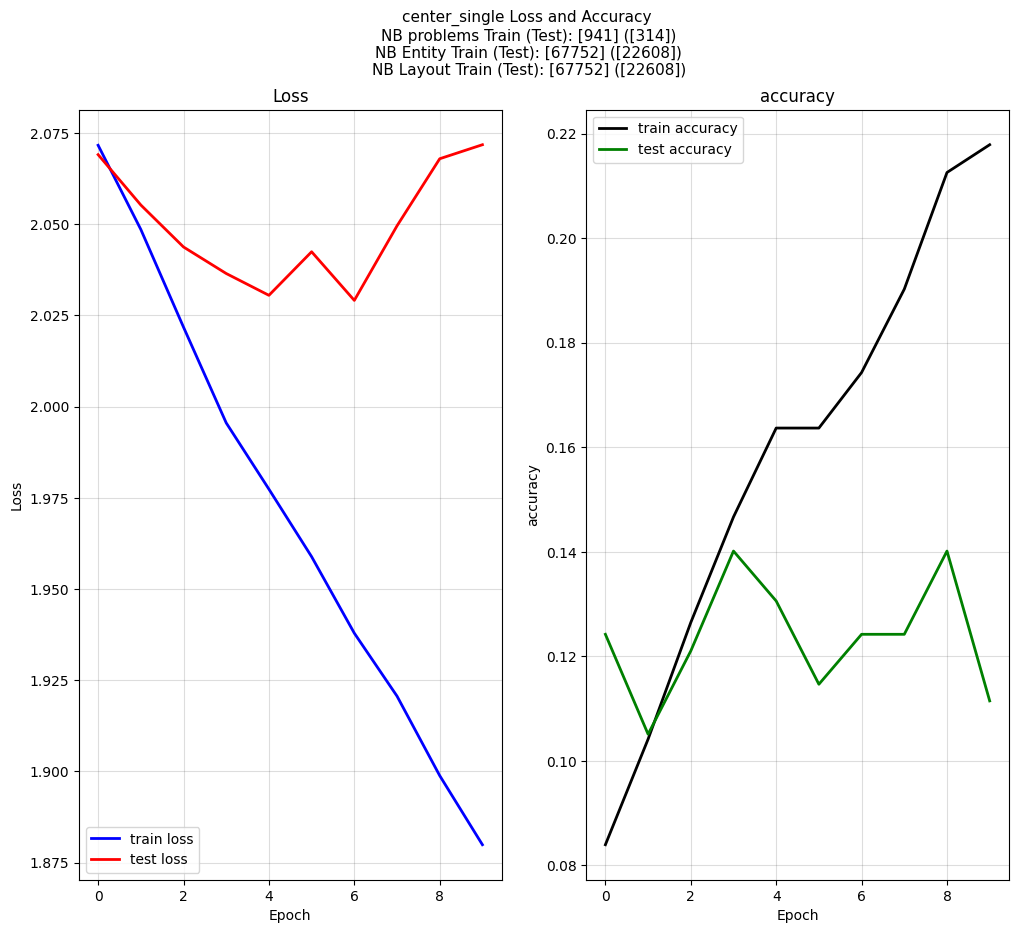

In [ ]:
# read json history_dict 
output_path = paths.get_output_path()
train_only=False
for config in Configuration.all()[:1]:
    # history_dict_path = output_path /"history"/"gnn"/f"training_history_{config}.json"
    # with open(history_dict_path, 'r') as json_file:
    #     history_dict = json.load(json_file)
        # print(history_dict)
    cfg_history_dict = history_dict[config]
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,10))
    subtitle = f"{config} Loss and Accuracy \n"
    subtitle +=f"NB problems Train (Test): {cfg_history_dict["train_number_of_problems"]} ({cfg_history_dict["test_number_of_problems"]})\n"
    subtitle +=f"NB Entity Train (Test): {cfg_history_dict["train_entity"]} ({cfg_history_dict["test_entity"]})\n" 
    subtitle +=f"NB Layout Train (Test): {cfg_history_dict["train_layout"]} ({cfg_history_dict["test_layout"]})" 

    fig.suptitle(subtitle, fontsize=11)
    axes[0].plot(range(epochs), cfg_history_dict['train_loss'] , color='blue', linewidth=2, label='train loss')
    if not train_only:
        axes[0].plot(range(epochs), cfg_history_dict['test_loss'] , color='red', linewidth=2, label='test loss')
    axes[0].set_title(f'Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.2, color='#555')
    axes[1].plot(range(epochs), cfg_history_dict['train_accuracy'],color="black",linewidth=2, label=f'train accuracy')
    if not train_only:
        axes[1].plot(range(epochs), cfg_history_dict['test_accuracy'],color="green",linewidth=2, label=f'test accuracy')
    axes[1].set_title(f'accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.2, color='#555')

    # gnn_curves_path = output_path/"metric_curves"/"gnn"/f"{config}_loss_accuracy.png"
    # plt.savefig(gnn_curves_path)
    # print(f"\n[OK] {config} curves saved to {gnn_curves_path}")



In [1]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

In [2]:
# Python imports 
import random 
from collections import defaultdict
from itertools import islice
from pprint import pp
import json

# PyTorch imports 
import torch
import torch.nn as nn 
from torch.utils.data import DataLoader

# matplotlib imports
import matplotlib.pyplot as plt 

# HRI_GNN imports
from hri_gnn.config.const import Configuration, SLOT_TABLE, MAX_SLOTS, GRAPH_NODE_TYPES, GRAPH_EDGE_TYPES
from hri_gnn.utils import paths
from hri_gnn.datasets import raven_flat_collate
from hri_gnn.datasets import RavenDataset
from hri_gnn.models.cnn_encoder import RavenCnnEncoder
from hri_gnn.models.gnn_encoder import RavenGnnModel 
from hri_gnn.trainers import GnnTrainer

In [ ]:
# from hri_gnn.datasets.precomputed import PrecomputedRavenDataset, precomputed_collate
# from hri_gnn.config.const import SPLITS
# torch.manual_seed(92)
# random.seed(92)

# DATASET = 'raven-20000'
# PERCENTAGE_LIMIT = 0.5
# BATCH_SIZE = 128

# active_configs = [Configuration.CENTER_SINGLE.value]

# datatsets_dict = {}
# dataloaders_dict = {}

# for config in active_configs:
#     for split in SPLITS:
#         datatsets_dict[f"{config}_{split}"] = PrecomputedRavenDataset(dataset=DATASET,
#                                               split=split,
#                                               percentage_limit=PERCENTAGE_LIMIT,
#                                               configs=[config])
#         dataloaders_dict[f"{config}_{split}"] = DataLoader(
#                                                 dataset=datatsets_dict[f"{config}_{split}"],
#                                                 batch_size=BATCH_SIZE,
#                                                 shuffle= split == 'train',
#                                                 collate_fn=precomputed_collate,
#                                                 num_workers=4)

In [22]:
from hri_gnn.datasets.precomputed import PrecomputedRavenDataset, precomputed_collate
from hri_gnn.config.const import SPLITS
torch.manual_seed(92)
random.seed(92)

DATASET = 'raven-20000'
PERCENTAGE_LIMIT = 0.2
BATCH_SIZE = 128

# active_configs = [Configuration.CENTER_SINGLE.value]

datatsets_dict = {}
dataloaders_dict = {}

# for config in active_configs:
for split in SPLITS:
    datatsets_dict[f"{split}"] = PrecomputedRavenDataset(dataset=DATASET,
                                          split=split,
                                          percentage_limit=PERCENTAGE_LIMIT,
                                          configs=None)
    dataloaders_dict[f"{split}"] = DataLoader(
                                            dataset=datatsets_dict[f"{split}"],
                                            batch_size=BATCH_SIZE,
                                            shuffle= split == 'train',
                                            collate_fn=precomputed_collate,
                                            num_workers=4,
                                            persistent_workers=True,
                                            pin_memory=True)

In [23]:
len(datatsets_dict['train'])

16283

In [8]:
# load the saved model 

output_path = paths.get_output_path()

raven_encoder = RavenCnnEncoder()

raven_encoder.load_state_dict(torch.load(f=output_path/'models'/'raven_cnn_encoder_final.pth'))

<All keys matched successfully>

In [17]:
output_path = paths.get_output_path()
paths.output_paths(output_path)

gnn_model = RavenGnnModel(GRAPH_NODE_TYPES, hidden_dim=64, num_layers=3, dropout=0.2).to("cuda")
optimizer = torch.optim.Adam(gnn_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=7, min_lr=1e-5
)

train_only = False
active_edge_types = None # all edges are activated
include_columns = True 
epochs = 100

history_dict = {}
# for config in active_configs:
print(f"Training ....")
# 1. Instantiate the GNN model (fresh instace for each config)
gnn_trainer = GnnTrainer(gnn_model, raven_encoder, optimizer, scheduler, metrics=None, node_types= None, 
                         active_edge_types= active_edge_types, 
                         include_columns=include_columns, device="cuda", output_path= output_path)
# 2. Train the GNN model
history = gnn_trainer.fit(dataloaders_dict["train"] , 
                                       dataloaders_dict["test"], 
                                       epochs=epochs, 
                                       max_grad_norm=1.0, 
                                       checkpoint_name_prefix = None,
                                       check_frequency=10,
                                       save_final_version= False,
                                       verbose=True, 
                                       train_only= train_only)
# 3. Saving the training history
history_path = output_path/"history"/"gnn"/f"training_history.json"
with open(history_path, 'w') as f:
    json.dump(history, f, indent=2)
print(f"\n[OK] Training history saved : {history_path}")
print("="*80)

Training ....


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1/100 - Train Loss: 1.9987 | Train Acc: 0.1496 | Test Loss: 1.8512 | Test Acc: 0.1692 | LR: 1.00e-03 ★
Epoch 2/100 - Train Loss: 1.8240 | Train Acc: 0.2264 | Test Loss: 1.7074 | Test Acc: 0.2487 | LR: 1.00e-03 ★
Epoch 3/100 - Train Loss: 1.7432 | Train Acc: 0.2594 | Test Loss: 1.6685 | Test Acc: 0.2657 | LR: 1.00e-03 ★
Epoch 4/100 - Train Loss: 1.7050 | Train Acc: 0.2753 | Test Loss: 1.6217 | Test Acc: 0.2815 | LR: 1.00e-03 ★
Epoch 5/100 - Train Loss: 1.6772 | Train Acc: 0.2859 | Test Loss: 1.6118 | Test Acc: 0.2896 | LR: 1.00e-03 ★
Epoch 6/100 - Train Loss: 1.6576 | Train Acc: 0.2926 | Test Loss: 1.5845 | Test Acc: 0.3008 | LR: 1.00e-03 ★
Epoch 7/100 - Train Loss: 1.6405 | Train Acc: 0.3022 | Test Loss: 1.5835 | Test Acc: 0.3040 | LR: 1.00e-03 ★
Epoch 8/100 - Train Loss: 1.6236 | Train Acc: 0.3080 | Test Loss: 1.5584 | Test Acc: 0.3181 | LR: 1.00e-03 ★
Epoch 9/100 - Train Loss: 1.6135 | Train Acc: 0.3104 | Test Loss: 1.5377 | Test Acc: 0.3210 | LR: 1.00e-03 ★
Epoch 10/100 - Trai


[OK] gnn curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\metric_curves\gnn\loss_accuracy.png


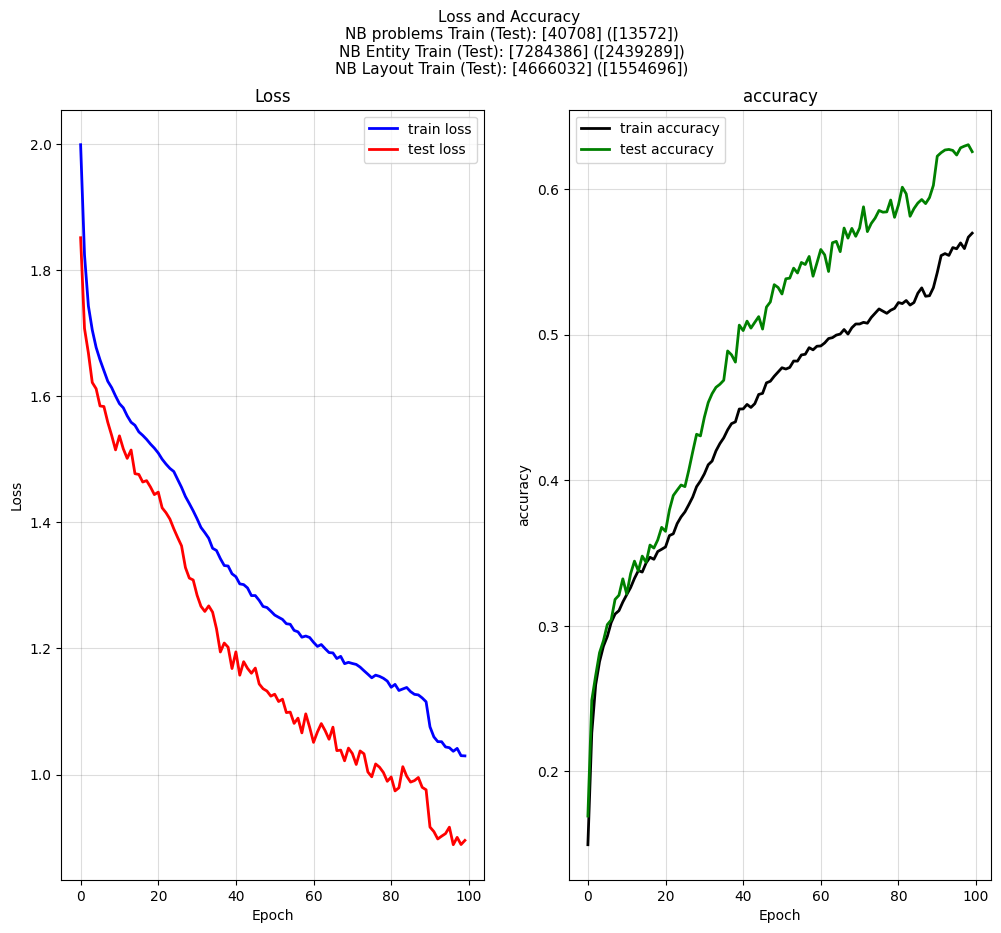

In [ ]:
# read json history_dict 
output_path = paths.get_output_path()
train_only=False
cfg_history_dict = history
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,10))
subtitle = f"Loss and Accuracy \n"
subtitle +=f"NB problems Train (Test): {cfg_history_dict["train_number_of_problems"]} ({cfg_history_dict["test_number_of_problems"]})\n"
subtitle +=f"NB Entity Train (Test): {cfg_history_dict["train_entity"]} ({cfg_history_dict["test_entity"]})\n" 
subtitle +=f"NB Layout Train (Test): {cfg_history_dict["train_layout"]} ({cfg_history_dict["test_layout"]})" 
fig.suptitle(subtitle, fontsize=11)
axes[0].plot(range(epochs), cfg_history_dict['train_loss'] , color='blue', linewidth=2, label='train loss')
if not train_only:
    axes[0].plot(range(epochs), cfg_history_dict['test_loss'] , color='red', linewidth=2, label='test loss')
axes[0].set_title(f'Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.2, color='#555')
axes[1].plot(range(epochs), cfg_history_dict['train_accuracy'],color="black",linewidth=2, label=f'train accuracy')
if not train_only:
    axes[1].plot(range(epochs), cfg_history_dict['test_accuracy'],color="green",linewidth=2, label=f'test accuracy')
axes[1].set_title(f'accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.2, color='#555')
gnn_curves_path = output_path/"metric_curves"/"gnn"/f"loss_accuracy.png"
plt.savefig(gnn_curves_path)
print(f"\n[OK] gnn curves saved to {gnn_curves_path}")



In [ ]:
# Load best checkpoint and keep going
gnn_model = RavenGnnModel(GRAPH_NODE_TYPES, hidden_dim=64, num_layers=3, dropout=0.2).to("cuda")
gnn_model.load_state_dict(torch.load(output_path/'models'/'gnn_model_best.pth'))

<All keys matched successfully>

In [ ]:
output_path = paths.get_output_path()
paths.output_paths(output_path)

gnn_model.to("cuda")
optimizer = torch.optim.Adam(gnn_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=7, min_lr=1e-5
)

train_only = False
active_edge_types = None # all edges are activated
include_columns = True 
epochs = 50

history_dict = {}

print(f"Training ....")
# 1. Instantiate the GNN model (fresh instace for each config)
gnn_trainer = GnnTrainer(gnn_model, raven_encoder, optimizer, scheduler, metrics=None, node_types= None, 
                         active_edge_types= active_edge_types, 
                         include_columns=include_columns, device="cuda", output_path= output_path)
# 2. Train the GNN model
history = gnn_trainer.fit(dataloaders_dict["train"] , 
                                       dataloaders_dict["test"], 
                                       epochs=epochs, 
                                       max_grad_norm=1.0, 
                                       checkpoint_name_prefix = None,
                                       check_frequency=10,
                                       save_final_version= False,
                                       verbose=True, 
                                       train_only= train_only)
# 3. Saving the training history
history_path = output_path/"history"/"gnn"/f"training_history_session_2.json"
with open(history_path, 'w') as f:
    json.dump(copy_history, f, indent=2)
print(f"\n[OK] Training history saved : {history_path}")
print("="*80)

Training ....


  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 1/50 - Train Loss: 1.0914 | Train Acc: 0.5430 | Test Loss: 0.9377 | Test Acc: 0.6118 | Test P: 0.6117 | Test R: 0.6117 | Test F1: 0.6117 | LR: 1.00e-03 ★
Epoch 2/50 - Train Loss: 1.1010 | Train Acc: 0.5422 | Test Loss: 0.9527 | Test Acc: 0.6037 | Test P: 0.6037 | Test R: 0.6037 | Test F1: 0.6036 | LR: 1.00e-03
Epoch 3/50 - Train Loss: 1.0998 | Train Acc: 0.5350 | Test Loss: 0.9496 | Test Acc: 0.6131 | Test P: 0.6130 | Test R: 0.6131 | Test F1: 0.6131 | LR: 1.00e-03 ★
Epoch 4/50 - Train Loss: 1.0931 | Train Acc: 0.5406 | Test Loss: 0.9441 | Test Acc: 0.6146 | Test P: 0.6146 | Test R: 0.6146 | Test F1: 0.6145 | LR: 1.00e-03 ★
Epoch 5/50 - Train Loss: 1.0992 | Train Acc: 0.5404 | Test Loss: 0.9212 | Test Acc: 0.6144 | Test P: 0.6143 | Test R: 0.6143 | Test F1: 0.6142 | LR: 1.00e-03
Epoch 6/50 - Train Loss: 1.0934 | Train Acc: 0.5425 | Test Loss: 0.9274 | Test Acc: 0.6171 | Test P: 0.6170 | Test R: 0.6171 | Test F1: 0.6170 | LR: 1.00e-03 ★
Epoch 7/50 - Train Loss: 1.0933 | Train Acc:

TypeError: Object of type Tensor is not JSON serializable

In [10]:
from hri_gnn.datasets.precomputed import PrecomputedRavenDataset, precomputed_collate
from hri_gnn.config.const import SPLITS
torch.manual_seed(92)
random.seed(92)

DATASET = 'raven-20000'
PERCENTAGE_LIMIT = 0.2
BATCH_SIZE = 128

# active_configs = [Configuration.CENTER_SINGLE.value]

datatsets_dict = {}
dataloaders_dict = {}

# for config in active_configs:
for split in SPLITS:
    datatsets_dict[f"{split}"] = PrecomputedRavenDataset(dataset=DATASET,
                                          split=split,
                                          percentage_limit=PERCENTAGE_LIMIT,
                                          configs=None)
    dataloaders_dict[f"{split}"] = DataLoader(
                                            dataset=datatsets_dict[f"{split}"],
                                            batch_size=BATCH_SIZE,
                                            shuffle= split == 'train',
                                            collate_fn=precomputed_collate,
                                            num_workers=4,
                                            persistent_workers=True,
                                            pin_memory=True)

In [32]:
len(datatsets_dict['train'])

16283

In [29]:
# Load best checkpoint and keep going
gnn_model = RavenGnnModel(GRAPH_NODE_TYPES, hidden_dim=64, num_layers=3, dropout=0.1).to("cuda")
gnn_model.load_state_dict(torch.load(output_path/'models'/'gnn_model_best.pth'))

<All keys matched successfully>

In [ ]:
output_path = paths.get_output_path()
paths.output_paths(output_path)

gnn_model.to("cuda")
optimizer = torch.optim.Adam(gnn_model.parameters(), lr=5e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=7, min_lr=1e-5
)

train_only = False
active_edge_types = None # all edges are activated
include_columns = True 
epochs = 10

history_dict = {}

print(f"Training ....")
# 1. Instantiate the GNN model (fresh instace for each config)
gnn_trainer = GnnTrainer(gnn_model, raven_encoder, optimizer, scheduler, metrics=None, node_types= None, 
                         active_edge_types= active_edge_types, 
                         include_columns=include_columns, device="cuda", output_path= output_path)
# 2. Train the GNN model
history = gnn_trainer.fit(dataloaders_dict["train"] , 
                                       dataloaders_dict["test"], 
                                       epochs=epochs, 
                                       max_grad_norm=1.0, 
                                       checkpoint_name_prefix = "seance_3",
                                       check_frequency=5,
                                       save_final_version= False,
                                       verbose=True, 
                                       train_only= train_only)
# 3. Saving the training history
history_path = output_path/"history"/"gnn"/f"training_history_session_3.json"
with open(history_path, 'w') as f:
    json.dump(history, f, indent=2)
print(f"\n[OK] Training history saved : {history_path}")
print("="*80)

Training ....


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/10 - Train Loss: 0.8476 | Train Acc: 0.6334 | Test Loss: 0.7705 | Test Acc: 0.6649 | Test P: 0.6644 | Test R: 0.6641 | Test F1: 0.6640 | LR: 5.00e-04 ★
Epoch 2/10 - Train Loss: 0.8207 | Train Acc: 0.6480 | Test Loss: 0.7522 | Test Acc: 0.6749 | Test P: 0.6748 | Test R: 0.6745 | Test F1: 0.6744 | LR: 5.00e-04 ★
Epoch 3/10 - Train Loss: 0.8061 | Train Acc: 0.6554 | Test Loss: 0.7561 | Test Acc: 0.6655 | Test P: 0.6651 | Test R: 0.6650 | Test F1: 0.6649 | LR: 5.00e-04
Epoch 4/10 - Train Loss: 0.8048 | Train Acc: 0.6567 | Test Loss: 0.7398 | Test Acc: 0.6810 | Test P: 0.6806 | Test R: 0.6803 | Test F1: 0.6803 | LR: 5.00e-04 ★
Epoch 5/10 - Train Loss: 0.7958 | Train Acc: 0.6573 | Test Loss: 0.7409 | Test Acc: 0.6795 | Test P: 0.6793 | Test R: 0.6791 | Test F1: 0.6790 | LR: 5.00e-04
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_seance_3_checkpoint_epoch_5.pth
Epoch 6/10 - Train Loss: 0.8013 | Train Acc: 0.6569 | Test Loss: 0.7361 | Tes

In [ ]:
# read json history_dict 
output_path = paths.get_output_path()
train_only=False
cfg_history_dict = history
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,10))
subtitle = f"Loss and Accuracy \n"
subtitle +=f"NB problems Train (Test): {cfg_history_dict["train_number_of_problems"]} ({cfg_history_dict["test_number_of_problems"]})\n"
subtitle +=f"NB Entity Train (Test): {cfg_history_dict["train_entity"]} ({cfg_history_dict["test_entity"]})\n" 
subtitle +=f"NB Layout Train (Test): {cfg_history_dict["train_layout"]} ({cfg_history_dict["test_layout"]})" 
fig.suptitle(subtitle, fontsize=11)
axes[0].plot(range(epochs), cfg_history_dict['train_loss'] , color='blue', linewidth=2, label='train loss')
if not train_only:
    axes[0].plot(range(epochs), cfg_history_dict['test_loss'] , color='red', linewidth=2, label='test loss')
axes[0].set_title(f'Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.2, color='#555')
axes[1].plot(range(epochs), cfg_history_dict['train_accuracy'],color="black",linewidth=2, label=f'train accuracy')
if not train_only:
    axes[1].plot(range(epochs), cfg_history_dict['test_accuracy'],color="green",linewidth=2, label=f'test accuracy')
axes[1].set_title(f'accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.2, color='#555')
gnn_curves_path = output_path/"metric_curves"/"gnn"/f"loss_accuracy.png"
plt.savefig(gnn_curves_path)
print(f"\n[OK] gnn curves saved to {gnn_curves_path}")

In [4]:
output_path = paths.get_output_path()
paths.output_paths(output_path)

In [5]:
# Load best checkpoint and keep going
gnn_model = RavenGnnModel(GRAPH_NODE_TYPES, hidden_dim=64, num_layers=3, dropout=0.1).to("cuda")
gnn_model.load_state_dict(torch.load(output_path/'models'/'gnn_model_best.pth'))

<All keys matched successfully>

In [11]:
gnn_model.to("cuda")
optimizer = torch.optim.Adam(gnn_model.parameters(), lr=5e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=7, min_lr=1e-5
)

train_only = False
active_edge_types = None # all edges are activated
include_columns = True 
epochs = 30

history_dict = {}

print(f"Training ....")
# 1. Instantiate the GNN model (fresh instace for each config)
gnn_trainer = GnnTrainer(gnn_model, raven_encoder, optimizer, scheduler, metrics=None, node_types= None, 
                         active_edge_types= active_edge_types, 
                         include_columns=include_columns, device="cuda", output_path= output_path)
# 2. Train the GNN model
history = gnn_trainer.fit(dataloaders_dict["train"] , 
                                       dataloaders_dict["test"], 
                                       epochs=epochs, 
                                       max_grad_norm=1.0, 
                                       checkpoint_name_prefix = "seance_4",
                                       check_frequency=5,
                                       save_final_version= False,
                                       verbose=True, 
                                       train_only= train_only)
# 3. Saving the training history
history_path = output_path/"history"/"gnn"/f"training_history_session_4.json"
with open(history_path, 'w') as f:
    json.dump(history, f, indent=2)
print(f"\n[OK] Training history saved : {history_path}")
print("="*80)

Training ....


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 1/30 - Train Loss: 0.8568 | Train Acc: 0.6311 | Test Loss: 0.7717 | Test Acc: 0.6648 | Test P: 0.6644 | Test R: 0.6644 | Test F1: 0.6642 | LR: 5.00e-04 ★
Epoch 2/30 - Train Loss: 0.8284 | Train Acc: 0.6514 | Test Loss: 0.7669 | Test Acc: 0.6659 | Test P: 0.6655 | Test R: 0.6654 | Test F1: 0.6653 | LR: 5.00e-04 ★
Epoch 3/30 - Train Loss: 0.8092 | Train Acc: 0.6503 | Test Loss: 0.7475 | Test Acc: 0.6716 | Test P: 0.6714 | Test R: 0.6712 | Test F1: 0.6711 | LR: 5.00e-04 ★
Epoch 4/30 - Train Loss: 0.7969 | Train Acc: 0.6579 | Test Loss: 0.7577 | Test Acc: 0.6727 | Test P: 0.6723 | Test R: 0.6723 | Test F1: 0.6721 | LR: 5.00e-04 ★
Epoch 5/30 - Train Loss: 0.7999 | Train Acc: 0.6558 | Test Loss: 0.7410 | Test Acc: 0.6813 | Test P: 0.6812 | Test R: 0.6811 | Test F1: 0.6809 | LR: 5.00e-04 ★
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_seance_4_checkpoint_epoch_5.pth
Epoch 6/30 - Train Loss: 0.7956 | Train Acc: 0.6592 | Test Loss: 0.7446 |

In [ ]:
# Python imports 
import random 
from collections import defaultdict
from itertools import islice
from pprint import pp
import json

# PyTorch imports 
import torch
import torch.nn as nn 
from torch.utils.data import DataLoader

# matplotlib imports
import matplotlib.pyplot as plt 

# HRI_GNN imports
from hri_gnn.config.const import Configuration, SLOT_TABLE, MAX_SLOTS, GRAPH_NODE_TYPES, GRAPH_EDGE_TYPES
from hri_gnn.utils import paths
from hri_gnn.datasets import raven_flat_collate
from hri_gnn.datasets import RavenDataset
from hri_gnn.models.cnn_encoder import RavenCnnEncoder
from hri_gnn.models.gnn_encoder import RavenGnnModel 
from hri_gnn.trainers import GnnTrainer

In [12]:
from hri_gnn.datasets.precomputed import PrecomputedRavenDataset, precomputed_collate
from hri_gnn.config.const import SPLITS
torch.manual_seed(92)
random.seed(92)

DATASET = 'raven-100'
PERCENTAGE_LIMIT = 1
BATCH_SIZE = 10

# active_configs = [Configuration.CENTER_SINGLE.value]

datatsets_dict = {}
dataloaders_dict = {}

# for config in active_configs:
for split in SPLITS:
    datatsets_dict[f"{split}"] = PrecomputedRavenDataset(dataset=DATASET,
                                          split=split,
                                          percentage_limit=PERCENTAGE_LIMIT,
                                          configs=None)
    dataloaders_dict[f"{split}"] = DataLoader(
                                            dataset=datatsets_dict[f"{split}"],
                                            batch_size=BATCH_SIZE,
                                            shuffle= split == 'train',
                                            collate_fn=precomputed_collate,
                                            num_workers=4,
                                            persistent_workers=True,
                                            pin_memory=True)

In [14]:
# load the saved model 

output_path = paths.get_output_path()

raven_encoder = RavenCnnEncoder()

raven_encoder.load_state_dict(torch.load(f=output_path/'models'/'raven_cnn_encoder_final.pth'))

<All keys matched successfully>

In [15]:
gnn_model = RavenGnnModel(GRAPH_NODE_TYPES, hidden_dim=64, num_layers=3, dropout=0.1).to("cuda")
optimizer = torch.optim.Adam(gnn_model.parameters(), lr=5e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=7, min_lr=1e-5
)

train_only = False
active_edge_types = None # all edges are activated
include_columns = True 
epochs = 30

history_dict = {}

print(f"Training on raven-100....")
# 1. Instantiate the GNN model (fresh instace for each config)
gnn_trainer = GnnTrainer(gnn_model, raven_encoder, optimizer, scheduler, metrics=None, node_types= None, 
                         active_edge_types= active_edge_types, 
                         include_columns=include_columns, device="cuda", output_path= output_path)
# 2. Train the GNN model
history = gnn_trainer.fit(dataloaders_dict["train"] , 
                                       dataloaders_dict["test"], 
                                       epochs=epochs, 
                                       max_grad_norm=1.0, 
                                       checkpoint_name_prefix = "seance_raven_100",
                                       check_frequency=5,
                                       save_final_version= False,
                                       verbose=True, 
                                       train_only= train_only)
# 3. Saving the training history
history_path = output_path/"history"/"gnn"/f"training_history_session_raven_100.json"
with open(history_path, 'w') as f:
    json.dump(history, f, indent=2)
print(f"\n[OK] Training history saved : {history_path}")
print("="*80)

Training on raven-100....


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 1/30 - Train Loss: 2.0811 | Train Acc: 0.1048 | Test Loss: 2.0806 | Test Acc: 0.0286 | Test P: 0.0271 | Test R: 0.0244 | Test F1: 0.0256 | LR: 5.00e-04 ★
Epoch 2/30 - Train Loss: 2.0738 | Train Acc: 0.1119 | Test Loss: 2.0751 | Test Acc: 0.0500 | Test P: 0.0464 | Test R: 0.0448 | Test F1: 0.0448 | LR: 5.00e-04 ★
Epoch 3/30 - Train Loss: 2.0548 | Train Acc: 0.1286 | Test Loss: 2.0595 | Test Acc: 0.0571 | Test P: 0.0504 | Test R: 0.0533 | Test F1: 0.0515 | LR: 5.00e-04 ★
Epoch 4/30 - Train Loss: 2.0298 | Train Acc: 0.1452 | Test Loss: 2.0342 | Test Acc: 0.0929 | Test P: 0.0896 | Test R: 0.0882 | Test F1: 0.0876 | LR: 5.00e-04 ★
Epoch 5/30 - Train Loss: 2.0088 | Train Acc: 0.1524 | Test Loss: 2.0320 | Test Acc: 0.1214 | Test P: 0.1270 | Test R: 0.1283 | Test F1: 0.1254 | LR: 5.00e-04 ★
 > Saved checkpoint: C:\Users\dhias\workspaces\these\HRI-GNN\outputs\checkpoints\gnn\gnn_model_seance_raven_100_checkpoint_epoch_5.pth
Epoch 6/30 - Train Loss: 2.0199 | Train Acc: 0.1452 | Test Loss: 